# Image fundamentals — the first lab

Load one plant photo and look at it three ways: as raw pixels, as color spaces,
and as a histogram. Everything here uses the same helpers the capture pipeline
uses (`plantvision.vision.io`, `plantvision.vision.colors`), so the notebook is
also a smoke test of the library.

In [1]:
%matplotlib inline

from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

from plantvision.vision.colors import hue_histogram, split_channels, to_gray, to_hsv
from plantvision.vision.io import image_info, load_image, save_image


def _repo_root() -> Path:
    """Locate the repo root whether the notebook runs from its own dir or the repo root."""
    here = Path.cwd()
    for candidate in (here, *here.parents):
        if (candidate / "pyproject.toml").exists():
            return candidate
    raise FileNotFoundError(f"pyproject.toml not found above {here}")


ROOT = _repo_root()
SAMPLE = ROOT / "curriculum" / "01-image-fundamentals" / "sample.jpg"
OUT_DIR = ROOT / "curriculum" / "01-image-fundamentals" / "output"
OUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"SAMPLE = {SAMPLE}")

SAMPLE = /home/codexrescriptus/devel/plantvision-lab/curriculum/01-image-fundamentals/sample.jpg


In [2]:
# Load the sample photo. Missing file -> ImageReadError from plantvision.vision.io.
img = load_image(SAMPLE)
print(f"BGR array: shape={img.shape}, dtype={img.dtype}")

BGR array: shape=(1280, 964, 3), dtype=uint8


In [3]:
# What are we holding? shape, dtype, value range.
info = image_info(img)
print(info)

{'height': 1280, 'width': 964, 'channels': 3, 'dtype': 'uint8', 'min': 0.0, 'max': 255.0, 'mean': 143.52460370202283}


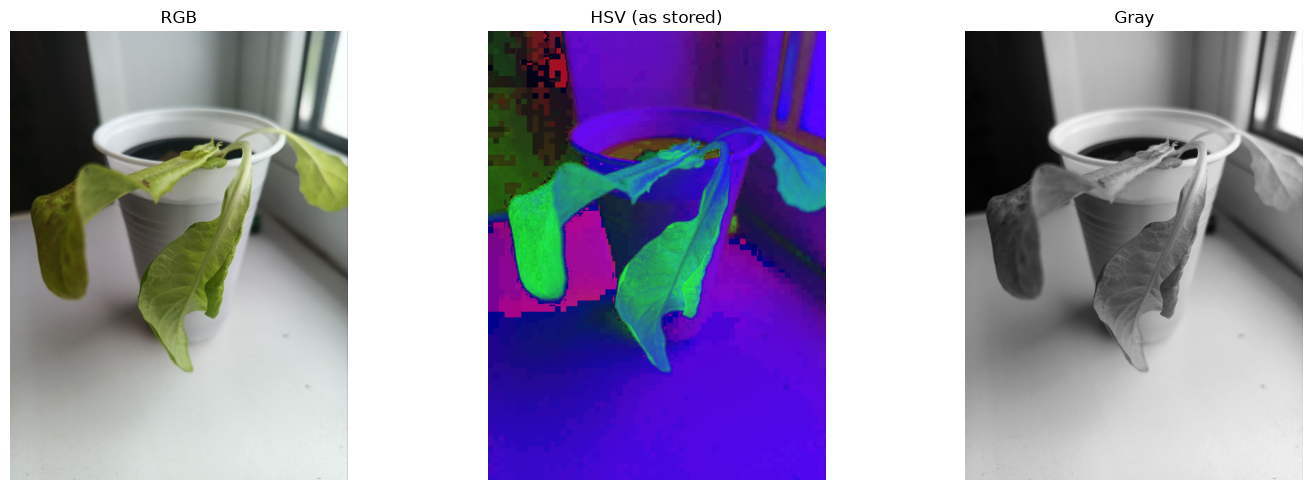

In [4]:
# The same image in three color spaces, side by side.
#   RGB  - what humans see (OpenCV loads BGR; reverse the channels to show it).
#   HSV  - separates hue (which color) from saturation/value (how much light).
#   gray - luminance only: what segmentation starts from.
rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
hsv = to_hsv(img)
gray = to_gray(img)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(rgb)
axes[0].set_title("RGB")
axes[1].imshow(hsv)
axes[1].set_title("HSV (as stored)")
axes[2].imshow(gray, cmap="gray")
axes[2].set_title("Gray")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

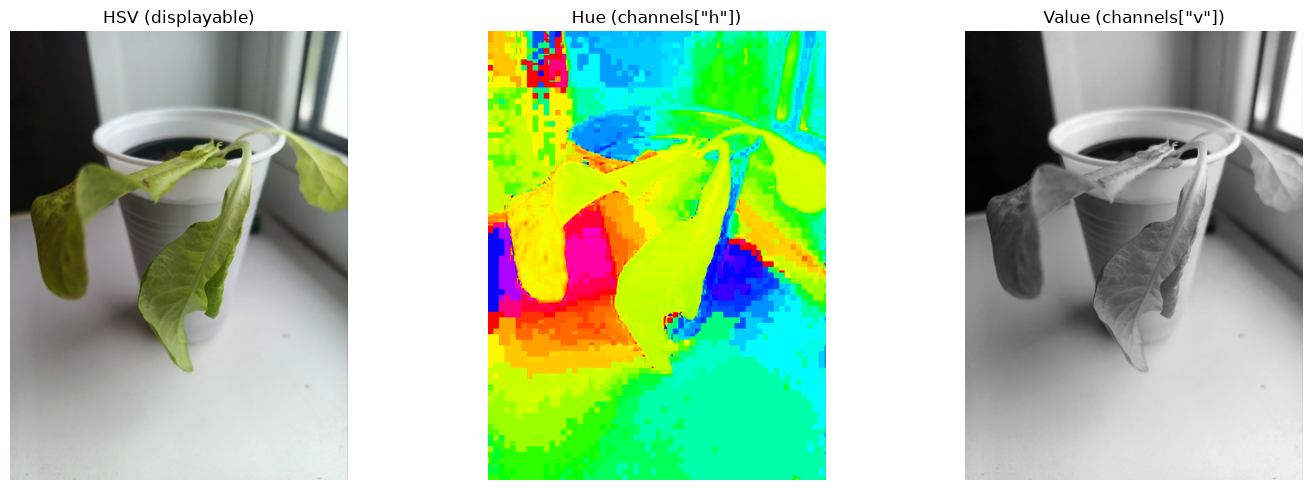

In [5]:
# Split the HSV image; show Hue and Value separately.
# Hue alone already isolates the green plant from the soil and the pot.
channels = split_channels(img, "hsv")
hsv_rgb = cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(hsv_rgb)
axes[0].set_title("HSV (displayable)")
axes[1].imshow(channels["h"], cmap="hsv")
axes[1].set_title('Hue (channels["h"])')
axes[2].imshow(channels["v"], cmap="gray")
axes[2].set_title('Value (channels["v"])')
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

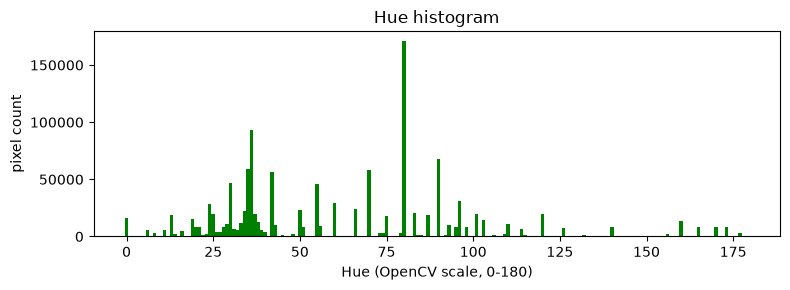

In [6]:
# Histogram of hue over [0, 180): the green foliage shows up as a distinct band.
hist, centers = hue_histogram(hsv)

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(centers, hist, width=1.0, color="green")
ax.set_title("Hue histogram")
ax.set_xlabel("Hue (OpenCV scale, 0-180)")
ax.set_ylabel("pixel count")
plt.tight_layout()
plt.show()

In [7]:
# Save the grayscale result; the same write path the pipeline uses for derived data.
OUT = OUT_DIR / "gray.png"
gray_path = save_image(to_gray(img), OUT)
print(f"saved: {gray_path}")

saved: /home/codexrescriptus/devel/plantvision-lab/curriculum/01-image-fundamentals/output/gray.png
